<div align="center">

## **DS201.R11 - DEEP LEARNING TRONG KHDL**

### **BÀI THỰC HÀNH 4: ENCODER–DECODER VÀ ATTENTION CHO DỊCH MÁY**
</div>

**Họ và tên:** Lương Trần Kim Ngọc

**MSSV:** 2424521157

Bộ dữ liệu sử dụng: [PhoMT](https://drive.google.com/drive/folders/186OAOuSEYEDVcry7WP5UBdqECXo26QAb?usp=drive_link).

## 1. Dữ liệu và cấu hình chung

In [1]:
import importlib.util
import subprocess
import sys

packages = {'rouge_score': 'rouge-score', 'sacrebleu': 'sacrebleu', 'gdown': 'gdown', 'reportlab': 'reportlab'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

# Import thư viện
import hashlib, json, random, time, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

# Cố định seed và chọn thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(torch.__version__, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else device)

# Cấu hình chung; Phần C đổi các giá trị có chú thích "Phần C"
cfg = dict(
    emb=256, hidden=256, layers=3,  # Phần C: 256, 256, 3
    dropout=0.3, batch=32, lr=1e-3, teacher_ratio=0.5,
    epochs=10,                     # Phần C: 10
    max_words=50,                 # Phần C: 50
    vocab_limit=10000,             # Phần C: 10000
    min_freq=2,
    train_limit=None,              # Phần C: None (toàn bộ train)
    dev_limit=None,                 # Phần C: None (toàn bộ dev)
)
display(pd.Series(cfg, name='Cấu hình'))

# Đường dẫn dữ liệu, thư mục lưu kết quả và id của 4 token đặc biệt
base = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
LAB = base/'Lab4' if (base/'Lab4').is_dir() else base
DATA = LAB/'data'
ART = LAB/'artifacts'
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
print('Dữ liệu:', DATA.name, '| kết quả lưu ở:', ART.name)

2.11.0+cu130 | Tesla T4


emb                256.000
hidden             256.000
layers               3.000
dropout              0.300
batch               32.000
lr                   0.001
teacher_ratio        0.500
epochs              10.000
max_words           50.000
vocab_limit      10000.000
min_freq             2.000
train_limit            NaN
dev_limit              NaN
Name: Cấu hình, dtype: float64

Dữ liệu: data | kết quả lưu ở: artifacts


In [2]:
# Danh sách tệp: tên, link tải và mã SHA-256
DATA_FILES = [{'file': 'small-train.json',
  'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
  'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
 {'file': 'small-dev.json',
  'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
  'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
 {'file': 'small-test.json',
  'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
  'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'}]

# Tải tệp còn thiếu, rồi kiểm tra SHA-256 của cả ba tệp
for item in DATA_FILES:
    path = DATA/item['file']
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        import tempfile
        import gdown
        with tempfile.TemporaryDirectory() as temp:
            download = Path(temp)/item['file']
            gdown.download(id=item['url'].split('id=')[-1], output=str(download), quiet=True)
            content = download.read_bytes()
        if hashlib.sha256(content).hexdigest() != item['sha256']:
            raise ValueError('Nguồn tải đổi hoặc trả về HTML: '+item['file'])
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
        raise ValueError('Checksum không khớp: '+item['file'])
print('3/3 tệp dữ liệu khớp SHA-256.')

# Chuẩn hóa: bỏ BOM, NFC, chữ thường, tách theo khoảng trắng
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()


# Đọc ba tệp, giữ cặp có cả hai phía dài từ 1 đến max_words token
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    path = DATA/f'small-{split}.json'
    raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(source) <= cfg['max_words'] and \
                1 <= len(target) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    print(split, '| tệp gốc:', len(raw[split]),
          '| sau lọc:', len(filtered[split]))

# Kiểm tra số cặp của ba bộ chia gốc
assert [len(raw[s]) for s in raw] == [20000, 2000, 2000]
assert all(filtered[s] for s in filtered)
print('Đúng schema và ba bộ chia gốc: PASS')

3/3 tệp dữ liệu khớp SHA-256.
train | tệp gốc: 20000 | sau lọc: 18607
dev | tệp gốc: 2000 | sau lọc: 1901
test | tệp gốc: 2000 | sau lọc: 1786
Đúng schema và ba bộ chia gốc: PASS


In [3]:
# Hàm xây từ điển: 4 token đặc biệt + token xuất hiện ít nhất min_freq lần
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq']
            and t not in SPECIAL][:cfg['vocab_limit']-4]
    return {token: i for i, token in enumerate(SPECIAL+keep)}

# Từ điển tiếng Anh (nguồn) và tiếng Việt (đích)
src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
assert all(src_vocab[t] == tgt_vocab[t] == i
           for i, t in enumerate(SPECIAL))
print('Từ điển Anh/Việt:', len(src_vocab), len(tgt_vocab))
print('Special IDs:', {t: src_vocab[t] for t in SPECIAL})

# Đổi token thành id; token chưa có trong từ điển phải thành UNK
def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

assert encode(['từ_không_có_thật'], tgt_vocab) == [UNK]
print('encode:', encode(['tôi', 'từ_không_có_thật'], tgt_vocab))

# Ghép batch: nguồn thêm EOS, đích thêm BOS/EOS, đệm PAD bên phải
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab)+[EOS]) for r in rows]
    tgt = [torch.tensor([BOS]+encode(r['tgt'], tgt_vocab)+[EOS])
           for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

# Lấy tập con cố định theo seed 42; limit=None nghĩa là dùng toàn bộ
def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    ids = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in ids]

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
print('Train/dev đang dùng:', len(train_rows), len(dev_rows))

# DataLoader có generator cố định để thứ tự batch giống nhau giữa các mô hình
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))

print('Số batch train mỗi epoch:', len(loader(train_rows)))

Từ điển Anh/Việt: 8943 4003
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}
encode: [6, 1]
Train/dev đang dùng: 18607 1901
Số batch train mỗi epoch: 582


## 2. Encoder, decoder và kiểm tra

In [4]:
# Encoder: Embedding -> LSTM có packing; trả memory và (h, c)
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state

# Hai kiểu tính điểm: Bahdanau (cộng) và Luong general (nhân)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask, keys):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + keys)
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(keys,
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

# Decoder chạy từng bước; mode = 'none', 'bahdanau' hoặc 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding, keys):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask, keys)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask, keys)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights

# Seq2Seq = Encoder + Decoder; teacher_ratio là xác suất dùng token đúng
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        attention = getattr(self.decoder, 'attn', None)
        keys = (attention.Wk(memory) if self.mode == 'bahdanau'
                else attention.W(memory) if self.mode == 'luong' else None)
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        if self.mode == 'none' and teacher_ratio == 1.0:
            dec = self.decoder
            out, _ = dec.rnn(dec.drop(dec.emb(tgt[:, :-1])), state)
            return dec.head(dec.drop(out))
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding, keys)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)

# Kiểm tra shape logits của ba mô hình
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
# Thử trên hai cặp câu tự tạo
toy = [dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
       dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))]
batch = collate(toy)
print('src:', tuple(batch['src'].shape),
      '| lengths:', batch['lengths'].tolist())
print('tgt:', tuple(batch['tgt'].shape))

def make_seq2seq(mode, **kwargs):
    kwargs = kwargs or model_cfg
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kwargs).to(device)

for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    model = make_seq2seq(mode)
    logits = model(batch['src'].to(device), batch['lengths'],
                   batch['tgt'].to(device), teacher_ratio=1.0)
    assert logits.shape[:2] == batch['tgt'][:, 1:].shape
    print(mode, '| logits:', tuple(logits.shape))



src: (2, 4) | lengths: [4, 2]
tgt: (2, 5)
none | logits: (2, 4, 4003)
bahdanau | logits: (2, 4, 4003)
luong | logits: (2, 4, 4003)


In [5]:
# Sinh từng token bằng argmax đến khi mọi câu gặp EOS hoặc hết max_steps
@torch.no_grad()
def generate(model, src, lengths, max_steps, return_weights=False):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    attention = getattr(model.decoder, 'attn', None)
    keys = (attention.Wk(memory) if model.mode == 'bahdanau'
            else attention.W(memory) if model.mode == 'luong' else None)
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding, keys)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if return_weights and weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights

# Đổi dãy id thành câu, dừng ở EOS và bỏ PAD/BOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)

print('decode:', decode(batch['tgt'][0]))

# Hàm loss bỏ qua vị trí PAD của câu đích
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

# Kiểm tra 1: đệm thêm PAD vào câu nguồn không làm đổi logits
src, tgt = batch['src'].to(device), batch['tgt'].to(device)
check_logits = {}
for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    check_model = make_seq2seq(mode).eval()
    with torch.no_grad():
        a = check_model(src, batch['lengths'], tgt, teacher_ratio=1.0)
        b = check_model(nn.functional.pad(src, (0, 12)),
                        batch['lengths'], tgt, teacher_ratio=1.0)
    torch.testing.assert_close(a, b, atol=1e-6, rtol=1e-5)
    check_logits[mode] = a
    print(mode, '| đệm thêm PAD: PASS')

# Kiểm tra 2: thêm nhãn PAD vào cuối câu đích không làm đổi loss
target = tgt[:, 1:]
more_target = nn.functional.pad(target, (0, 2), value=PAD)
for mode, a in check_logits.items():
    loss1 = criterion(a.reshape(-1, len(tgt_vocab)), target.reshape(-1))
    noise = torch.randn(a.size(0), 2, a.size(2), device=device)
    more_logits = torch.cat([a, noise], dim=1)
    loss2 = criterion(more_logits.reshape(-1, len(tgt_vocab)),
                      more_target.reshape(-1))
    torch.testing.assert_close(loss1, loss2)
    print(mode, '| loss bỏ qua PAD: PASS')

with torch.no_grad():
    for mode in ['bahdanau', 'luong']:
        check_model = make_seq2seq(mode)
        _, weights = generate(check_model, src, batch['lengths'], 4, return_weights=True)
        torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights.sum(-1)))
        assert (weights.masked_select((src == PAD).unsqueeze(1)) == 0).all()
    display(pd.DataFrame({'attention': ['Bahdanau', 'Luong'], 'mask PAD': [True, True]}))


decode: tôi yêu bạn
none | đệm thêm PAD: PASS
bahdanau | đệm thêm PAD: PASS
luong | đệm thêm PAD: PASS
none | loss bỏ qua PAD: PASS
bahdanau | loss bỏ qua PAD: PASS
luong | loss bỏ qua PAD: PASS


,attention,mask PAD
0,Bahdanau,True
1,Luong,True


## 3.Huấn luyện và đánh giá
ROUGE-L tính F1 trung bình theo câu, dùng tokenizer giữ dấu tiếng Việt. Bản dịch được sinh greedy từ câu nguồn. Cross-entropy bỏ PAD. Cùng seed và thứ tự batch cho cả ba mô hình.

In [6]:
# ROUGE-L với tokenizer giữ dấu tiếng Việt, không stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())
print(UnicodeTokens().tokenize('Tiếng Việt có dấu'))

# Trung bình ROUGE-L theo câu, kèm BLEU corpus để tham khảo
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score, bleu_signature=str(bleu.get_signature()))

# Kiểm tra: câu dịch trùng câu tham chiếu thì ROUGE-L F1 = 1
example = translation_metrics(['tôi yêu bạn'], ['tôi yêu bạn'])
assert example['rougeL_f1'] == 1.0
print('ROUGE-L F1 khi khớp hoàn toàn:', example['rougeL_f1'])

# Đánh giá: dev-NLL (có câu đích) và ROUGE-L/BLEU trên câu sinh bằng generate
@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hypotheses, references = [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        target = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)), target.reshape(-1),
            ignore_index=PAD, reduction='sum').item()
        count += int((target != PAD).sum())
        generated, _ = generate(model, src, b['lengths'], cfg['max_words']+1)
        hypotheses.extend(decode(row) for row in generated.cpu())
        references.extend(b['refs'])
    metrics = translation_metrics(hypotheses, references)
    metrics['dev_nll'] = nll/count
    return metrics

# Huấn luyện một epoch, trả loss trung bình trên token thật
def train_epoch(model, train_loader, optimizer, scaler):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.float().reshape(-1, len(tgt_vocab)),
                         gold.reshape(-1))
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        n = int((gold != PAD).sum())
        loss_total += loss.item()*n
        tokens_total += n
    return loss_total/tokens_total

# Vòng huấn luyện: mỗi epoch train rồi chấm dev, giữ checkpoint tốt nhất
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1., float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs']+1):
        seed_all(42+epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer, scaler)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter()-start
        measured = evaluate(model, dev_rows)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss,
                            seconds=seconds, **measured))
        print(f"{name} epoch {epoch}: loss={train_loss:.4f} "
              f"dev_ROUGE-L={measured['rougeL_f1']:.4f} "
              f"BLEU={measured['bleu']:.2f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    return history, best_epoch

['tiếng', 'việt', 'có', 'dấu']
ROUGE-L F1 khi khớp hoàn toàn: 1.0


#### Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

### Encoder–Decoder LSTM

In [7]:
seed_all()
models, histories, best_epochs = {}, {}, {}
mode = 'none'
model = make_seq2seq(mode)
assert model.encoder.rnn.num_layers == model.decoder.rnn.num_layers == 3
assert model.encoder.rnn.hidden_size == model.decoder.rnn.hidden_size == 256
histories[mode], best_epochs[mode] = fit(model, mode)
models[mode] = model
display(pd.DataFrame(histories[mode]).drop(columns='bleu_signature').round(4))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 1: loss=6.0197 dev_ROUGE-L=0.1278 BLEU=0.07


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 2: loss=5.7074 dev_ROUGE-L=0.1585 BLEU=0.58


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 3: loss=5.5187 dev_ROUGE-L=0.1787 BLEU=1.10


... (11 outputs left out)

none epoch 9: loss=4.9416 dev_ROUGE-L=0.2224 BLEU=2.06


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 10: loss=4.8803 dev_ROUGE-L=0.2277 BLEU=2.29


,epoch,train_loss,seconds,rougeL_f1,rougeL_precision,rougeL_recall,bleu,dev_nll
0,1,6.0197,104.8087,0.1278,0.1463,0.1154,0.0704,5.8893
1,2,5.7074,103.2339,0.1585,0.1848,0.1412,0.5804,5.6072
2,3,5.5187,103.1983,0.1787,0.2025,0.1628,1.1009,5.3994
3,4,5.3765,103.6011,0.1962,0.2230,0.1777,1.2423,5.2526
4,5,5.2597,103.4201,0.2049,0.2348,0.1844,1.5487,5.1322
5,6,5.1639,104.1583,0.2127,0.2396,0.1941,1.7494,5.0449
6,7,5.0816,104.8428,0.2149,0.2393,0.1979,1.8573,4.9688
7,8,5.0069,104.2839,0.2207,0.2459,0.2031,1.9435,4.9024
8,9,4.9416,104.4145,0.2224,0.2452,0.2065,2.0564,4.8457
9,10,4.8803,102.5732,0.2277,0.2551,0.2085,2.2904,4.7975


#### Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

### Bahdanau attention

In [8]:
seed_all()
mode = 'bahdanau'
model = make_seq2seq(mode)
assert model.encoder.rnn.num_layers == model.decoder.rnn.num_layers == 3
assert model.encoder.rnn.hidden_size == model.decoder.rnn.hidden_size == 256
histories[mode], best_epochs[mode] = fit(model, mode)
models[mode] = model
display(pd.DataFrame(histories[mode]).drop(columns='bleu_signature').round(4))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 1: loss=6.0445 dev_ROUGE-L=0.1378 BLEU=0.13


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 2: loss=5.6603 dev_ROUGE-L=0.1930 BLEU=0.97


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 3: loss=5.3734 dev_ROUGE-L=0.2206 BLEU=1.71


... (11 outputs left out)

bahdanau epoch 9: loss=4.5701 dev_ROUGE-L=0.2928 BLEU=4.33


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 10: loss=4.4888 dev_ROUGE-L=0.2980 BLEU=4.53


,epoch,train_loss,seconds,rougeL_f1,rougeL_precision,rougeL_recall,bleu,dev_nll
0,1,6.0445,141.5208,0.1378,0.1595,0.1235,0.1297,5.9153
1,2,5.6603,142.9235,0.1930,0.2202,0.1746,0.9703,5.5005
2,3,5.3734,145.3114,0.2206,0.2430,0.2055,1.7113,5.2426
3,4,5.1688,142.3546,0.2430,0.2735,0.2218,2.2485,5.0532
4,5,5.0048,143.9984,0.2534,0.2780,0.2363,2.7842,4.9125
5,6,4.8731,145.3228,0.2652,0.2915,0.2468,3.2734,4.7897
6,7,4.7606,146.3298,0.2741,0.2966,0.2585,3.6982,4.7045
7,8,4.6586,140.9344,0.2852,0.3075,0.2701,4.0570,4.6116
8,9,4.5701,141.4622,0.2928,0.3113,0.2805,4.3281,4.5550
9,10,4.4888,140.4131,0.2980,0.3203,0.2826,4.5313,4.5018


#### Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

### Luong global-general attention

In [9]:
seed_all()
mode = 'luong'
model = make_seq2seq(mode)
assert model.encoder.rnn.num_layers == model.decoder.rnn.num_layers == 3
assert model.encoder.rnn.hidden_size == model.decoder.rnn.hidden_size == 256
histories[mode], best_epochs[mode] = fit(model, mode)
models[mode] = model
display(pd.DataFrame(histories[mode]).drop(columns='bleu_signature').round(4))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 1: loss=6.0703 dev_ROUGE-L=0.1276 BLEU=0.11


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 2: loss=5.7219 dev_ROUGE-L=0.1778 BLEU=0.93


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 3: loss=5.4448 dev_ROUGE-L=0.2052 BLEU=1.49


... (11 outputs left out)

luong epoch 9: loss=4.5956 dev_ROUGE-L=0.2904 BLEU=4.46


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 10: loss=4.5059 dev_ROUGE-L=0.2946 BLEU=4.71


,epoch,train_loss,seconds,rougeL_f1,rougeL_precision,rougeL_recall,bleu,dev_nll
0,1,6.0703,129.4821,0.1276,0.1478,0.1141,0.1128,5.9599
1,2,5.7219,128.8928,0.1778,0.2012,0.1617,0.9255,5.5887
2,3,5.4448,129.2465,0.2052,0.2277,0.1897,1.4888,5.3132
3,4,5.2383,129.0835,0.2331,0.2628,0.2124,2.1041,5.0993
4,5,5.0576,129.7525,0.2430,0.2706,0.2237,2.5686,4.9319
5,6,4.9133,129.5020,0.2613,0.2879,0.2429,3.2080,4.7945
6,7,4.7933,130.3755,0.2719,0.2983,0.2535,3.6008,4.7047
7,8,4.6877,129.9285,0.2803,0.3044,0.2637,3.9958,4.6066
8,9,4.5956,129.9446,0.2904,0.3144,0.2737,4.4601,4.5306
9,10,4.5059,130.0602,0.2946,0.3169,0.2791,4.7074,4.4771


## Biểu đồ và kết quả test

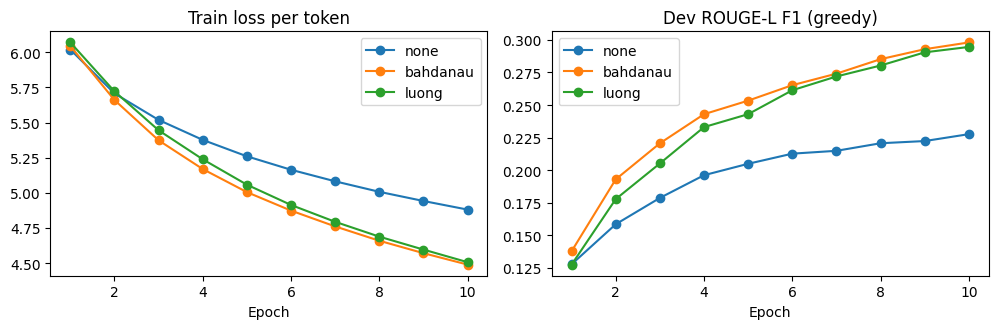

In [10]:
# Vẽ loss train và ROUGE-L dev theo epoch
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, records in histories.items():
    h = pd.DataFrame(records)
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=name)
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', label=name)
titles = ['Train loss per token', 'Dev ROUGE-L F1 (greedy)']
for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
fig.tight_layout()
fig.savefig(ART/'learning_curves.png', dpi=150)
plt.show()

In [11]:
# Lưu cấu hình, từ điển và id các cặp đã dùng vào metadata.json
metadata = dict(config=cfg, seed=42, device=str(device),
                normalization='NFC; remove BOM; lowercase; whitespace',
                src_vocab=src_vocab, tgt_vocab=tgt_vocab, files=DATA_FILES,
                selected_train_ids=[r['id'] for r in train_rows],
                selected_dev_ids=[r['id'] for r in dev_rows],
                histories=histories, best_epochs=best_epochs)
text = json.dumps(metadata, ensure_ascii=False, indent=2)
(ART/'metadata.json').write_text(text, encoding='utf-8')
print('Đã lưu metadata.json và', len(models), 'checkpoint .pt')

# Nạp lại checkpoint Bahdanau và so logits với mô hình đang có
restored = make_seq2seq('bahdanau')
state = torch.load(ART/'bahdanau.pt', map_location=device, weights_only=True)
restored.load_state_dict(state)
restored.eval()
b = collate(toy)
with torch.no_grad():
    args = (b['src'].to(device), b['lengths'], b['tgt'].to(device))
    a = restored(*args, teacher_ratio=1.0)
    c = models['bahdanau'](*args, teacher_ratio=1.0)
torch.testing.assert_close(a, c)
print('Nạp lại checkpoint, từ điển và metadata: PASS')

Đã lưu metadata.json và 3 checkpoint .pt
Nạp lại checkpoint, từ điển và metadata: PASS


## Đánh giá (Test) và bảng tổng hợp kết quả

In [12]:
results = []
predictions = {}
for name, model in models.items():
    hypotheses = []
    for b in loader(filtered['test']):
        ids, _ = generate(model, b['src'].to(device), b['lengths'], cfg['max_words']+1)
        hypotheses.extend(decode(row) for row in ids.cpu())
    predictions[name] = hypotheses
    references = [' '.join(r['tgt']) for r in filtered['test']]
    score = translation_metrics(hypotheses, references)
    best = histories[name][best_epochs[name] - 1]
    results.append(dict(model=name, ROUGE_L_dev=best['rougeL_f1'],
                        ROUGE_L_test=score['rougeL_f1'],
                        parameters=sum(p.numel() for p in model.parameters()),
                        seconds_per_epoch=np.mean([h['seconds'] for h in histories[name]])))
comparison = pd.DataFrame(results)
comparison.to_csv(ART/'comparison_test.csv', index=False)
display(comparison.round(4))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,ROUGE_L_dev,ROUGE_L_test,parameters,seconds_per_epoch
0,none,0.2277,0.2336,7500963,103.8535
1,bahdanau,0.2980,0.3126,8025763,143.0571
2,luong,0.2946,0.3102,7959971,129.6268


## Câu dịch mẫu và heatmap
Chọn câu có ROUGE-L cao nhất, gần trung vị và thấp nhất trong cùng nhóm câu nguồn. Đọc bản dịch cùng câu nguồn và tham chiếu để xem mô hình giữ hoặc bỏ sót nội dung nào.

In [13]:
samples = {}
for name, hypotheses in predictions.items():
    candidates = [(rouge.score(ref, hyp)['rougeL'].fmeasure, i)
                  for i, (ref, hyp) in enumerate(zip(references, hypotheses))
                  if 4 <= len(filtered['test'][i]['src']) <= 15]
    ranked = sorted(candidates)
    samples[name] = []
    for label, (f1, i) in zip(['Cao', 'Trung vị', 'Thấp'],
                             [ranked[-1], ranked[len(ranked)//2], ranked[0]]):
        hyp, ref = hypotheses[i], references[i]
        missing = list(dict.fromkeys(t for t in tokens(ref) if t not in tokens(hyp)))
        note = ('Khớp tham chiếu.' if hyp == ref else
                'Thiếu token tham chiếu: ' + ', '.join(missing[:6]) if missing else
                'Có đủ token tham chiếu nhưng chuỗi khác.')
        samples[name].append(dict(mức=label, id=filtered['test'][i]['id'],
                                  nguồn=' '.join(filtered['test'][i]['src']),
                                  tham_chiếu=ref, bản_dịch=hyp, ROUGE_L=round(f1, 4),
                                  nhận_xét=note, index=i))
    display(pd.DataFrame(samples[name]).drop(columns='index').assign(model=name))

,mức,id,nguồn,tham_chiếu,bản_dịch,ROUGE_L,nhận_xét,model
0,Cao,907,( laughter ) ( applause ) thank you .,( cười ) ( vỗ tay ) cám ơn .,( cười ) ( vỗ tay ) cảm ơn .,0.9000,Thiếu token tham chiếu: cám,none
1,Trung vị,1473,they were n't willing to engage in this .,họ không cần quan tâm tới những thứ như câu hỏ...,họ không phải làm điều đó .,0.2857,"Thiếu token tham chiếu: cần, quan, tâm, tới, n...",none
2,Thấp,46,it therefore needs to be revised as soon as po...,"vì thế , cần phải điều chỉnh lại càng sớm càng...",nó có thể làm được được những người không,0.0000,"Thiếu token tham chiếu: vì, thế, ,, cần, phải,...",none


,mức,id,nguồn,tham_chiếu,bản_dịch,ROUGE_L,nhận_xét,model
0,Cao,1923,do n't worry .,đừng lo lắng .,đừng lo lắng .,1.0000,Khớp tham chiếu.,bahdanau
1,Trung vị,1610,"every time we try , we just get more informati...","mỗi lần ta cố , ta lại có thêm nhiều thông tin...","mỗi khi chúng ta chúng ta , chúng ta sẽ nhiều ...",0.3529,"Thiếu token tham chiếu: lần, cố, lại, có, thêm...",bahdanau
2,Thấp,75,dismantling saigon 's binh trieu tollgates fin...,đã hoàn thành việc tháo dỡ các trạm thu phí bì...,<unk> <unk> <unk> <unk> <unk> <unk> .,0.0000,"Thiếu token tham chiếu: đã, hoàn, thành, việc,...",bahdanau


,mức,id,nguồn,tham_chiếu,bản_dịch,ROUGE_L,nhận_xét,model
0,Cao,968,"so , thank you .","vâng , cảm ơn .","vâng , cảm ơn .",1.0000,Khớp tham chiếu.,luong
1,Trung vị,1910,we need to secure our text messages .,ta cần giữ an toàn cho các tin nhắn của ta .,chúng ta cần phải phải yêu vệ của mình .,0.3636,"Thiếu token tham chiếu: giữ, an, toàn, cho, cá...",luong
2,Thấp,65,v - pop prince 's documentary soundtrack among...,nhạc phim tài liệu của hoàng tử v-pop lọt vào ...,<unk> <unk> - <unk> <unk> <unk> <unk> <unk> <u...,0.0000,"Thiếu token tham chiếu: nhạc, phim, tài, liệu,...",luong


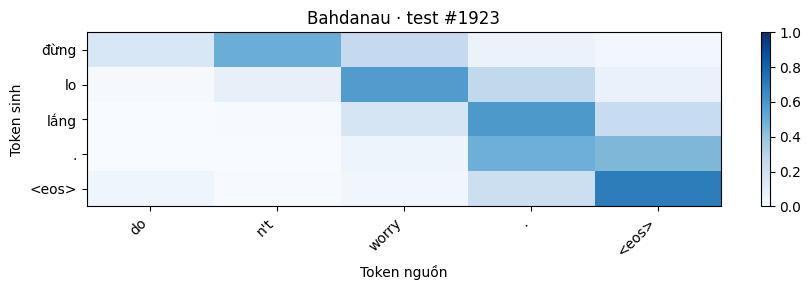

,token sinh,nguồn có trọng số cao nhất,trọng số
0,đừng,n't,0.503
1,lo,worry,0.576
2,lắng,.,0.591
3,.,.,0.494
4,<eos>,<eos>,0.703


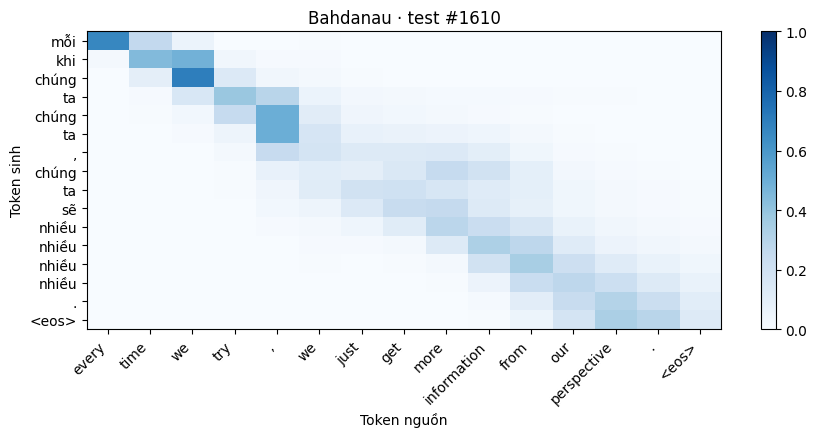

,token sinh,nguồn có trọng số cao nhất,trọng số
0,mỗi,every,0.668
1,khi,we,0.482
2,chúng,we,0.699
3,ta,try,0.385
4,chúng,",",0.497
5,ta,",",0.499
6,",",",",0.243
7,chúng,more,0.248
8,ta,get,0.200
9,sẽ,more,0.251


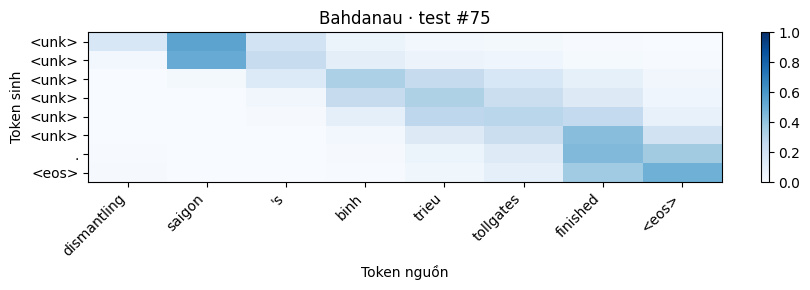

,token sinh,nguồn có trọng số cao nhất,trọng số
0,<unk>,saigon,0.546
1,<unk>,saigon,0.511
2,<unk>,binh,0.328
3,<unk>,trieu,0.322
4,<unk>,tollgates,0.287
5,<unk>,finished,0.428
6,.,finished,0.447
7,<eos>,<eos>,0.489


In [14]:
for j, example in enumerate(samples['bahdanau'], 1):
    row = filtered['test'][example['index']]
    b = collate([row])
    ids, weights = generate(models['bahdanau'], b['src'].to(device),
                            b['lengths'], cfg['max_words']+1, return_weights=True)
    shown = ids[0].tolist()
    stop = shown.index(EOS)+1 if EOS in shown else len(shown)
    matrix = weights[0, :stop, :b['lengths'][0]].cpu().numpy()
    np.testing.assert_allclose(matrix.sum(-1), 1, atol=1e-6)
    fig, ax = plt.subplots(figsize=(9, max(3, stop * 0.28)))
    image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
    ax.set_xticks(range(matrix.shape[1]), row['src']+['<eos>'], rotation=45, ha='right')
    ax.set_yticks(range(stop), [tgt_itos[i] for i in shown[:stop]])
    ax.set(xlabel='Token nguồn', ylabel='Token sinh', title=f"Bahdanau · test #{row['id']}")
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(ART/f'attention_{j}.png', dpi=150)
    plt.show()
    peaks = matrix.argmax(axis=1)
    labels = row['src'] + ['<eos>']
    display(pd.DataFrame({'token sinh': [tgt_itos[i] for i in shown[:stop]],
                          'nguồn có trọng số cao nhất': [labels[i] for i in peaks],
                          'trọng số': matrix.max(axis=1).round(3)}))

In [15]:
winner = comparison.loc[comparison.ROUGE_L_test.idxmax()]
baseline = comparison.loc[comparison.model.eq('none'), 'ROUGE_L_test'].iloc[0]
gain = winner.ROUGE_L_test - baseline
from IPython.display import Markdown
display(Markdown(
    f"**{winner.model}** đạt ROUGE-L test cao nhất ({winner.ROUGE_L_test:.4f}). "
    f"Chênh lệch so với LSTM cơ sở là {gain:+.4f}. " +
    ("Attention cho phép decoder lấy lại thông tin từ từng vị trí nguồn ở mỗi bước, "
     "có thể góp phần vào mức tăng quan sát được." if gain > 0 else
     "Trong lần chạy này, các decoder attention chưa cải thiện điểm test so với LSTM cơ sở.")
))
(ART/'samples.json').write_text(json.dumps(samples, ensure_ascii=False, indent=2), encoding='utf-8')
display(comparison.round(4))

**bahdanau** đạt ROUGE-L test cao nhất (0.3126). Chênh lệch so với LSTM cơ sở là +0.0790. Attention cho phép decoder lấy lại thông tin từ từng vị trí nguồn ở mỗi bước, có thể góp phần vào mức tăng quan sát được.

,model,ROUGE_L_dev,ROUGE_L_test,parameters,seconds_per_epoch
0,none,0.2277,0.2336,7500963,103.8535
1,bahdanau,0.2980,0.3126,8025763,143.0571
2,luong,0.2946,0.3102,7959971,129.6268
